# Setup

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

from pathlib import Path
from copy import deepcopy
import multiprocessing as mp
import logging
import random

import mlflow
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import numpy as np
from dotenv import load_dotenv

from halcyon.results.manipulate_results_df import (create_tidy_df_from_mlflow_runs, 
                                                   split_df_into_single_and_double_ko,
                                                   add_model_name_to_df)

from halcyon.results.plot_from_df import plot_model_plots, plot_per_gene_mse_heatmap, rotate_x_tick_labels, wrap_titles

from halcyon.results.DfColumnNames import DfColumnNames

seed = 174
# for CPU
torch.manual_seed(seed)              
# for all GPUs
torch.cuda.manual_seed_all(seed)     
np.random.seed(seed) 
random.seed(seed) 

load_dotenv() 

logging.basicConfig(
    level=logging.INFO, 
    format='%(asctime)s - %(levelname)s - %(message)s',
    force=True  # Important in Jupyter to reset config
)

# Load from MLFlow

In [2]:
print(mlflow.get_tracking_uri())
[f"{experiment.name=}" for experiment in mlflow.search_experiments()]
mlflow.set_experiment("Halcyon sandbox experiment")
mlflow.set_experiment_tag("Tool name", "HALCYON") 

https://mlflow.cropresilience.org


In [3]:
simulation_run_id_to_use = "d03e0d627633471fa8f99ffebd9b4bb4"

run = mlflow.get_run(simulation_run_id_to_use)

params = run.data.params
print(params)
print(run.data.tags.get('mlflow.source.git.commit'))

{'nr_genes': '100', 'sparsity': '0.1', 'num_modules': '10', 'noise_level': 'ALLNOISE', 'seed': '174'}
None


In [4]:
parent_run_id_search_string = f"tags.mlflow.parentRunId= '{simulation_run_id_to_use}'" 
runs_to_download = mlflow.search_runs(filter_string=parent_run_id_search_string, output_format="list")

In [ ]:
len(runs_to_download)

In [ ]:
runs_to_download[0].data.params

In [5]:
raw_df_download = create_tidy_df_from_mlflow_runs(runs_to_download)
with_model_name = add_model_name_to_df(raw_df_download)

2026-02-19 11:28:19,983 - INFO - Downloading artifacts for run 48a00979ed684cdd8f05a44a04c1e216


2026-02-19 11:28:21,077 - INFO - Downloading artifacts for run 623f0b1cd9ee44c9889f4632e7d2d6f0


2026-02-19 11:28:22,105 - INFO - Downloading artifacts for run 6f4dac0e7fc14bd6b7583d3e77d32eb2


2026-02-19 11:28:23,158 - INFO - Downloading artifacts for run d09a416277f448ca9a73b5cfcd0896bd


2026-02-19 11:28:24,206 - INFO - Downloading artifacts for run 3399da5f51854a9ab23adc752d87d0ed


2026-02-19 11:28:25,232 - INFO - Downloading artifacts for run b6c4a1b3ffb84f6f89de87d25fcfed65


2026-02-19 11:28:26,236 - INFO - Downloading artifacts for run f727643268074ac0b19accbadc8c9089


2026-02-19 11:28:27,256 - INFO - Downloading artifacts for run 038a882fb5944c01bb770fbe17e36f03


2026-02-19 11:28:28,384 - INFO - Getting model name for run_id 48a00979ed684cdd8f05a44a04c1e216
2026-02-19 11:28:28,535 - INFO - Getting model name for run_id 623f0b1cd9ee44c9889f4632e7d2d6f0
2026-02-19 11:28:28,682 - INFO - Getting model name for run_id 6f4dac0e7fc14bd6b7583d3e77d32eb2
2026-02-19 11:28:28,830 - INFO - Getting model name for run_id d09a416277f448ca9a73b5cfcd0896bd
2026-02-19 11:28:28,978 - INFO - Getting model name for run_id 3399da5f51854a9ab23adc752d87d0ed
2026-02-19 11:28:29,128 - INFO - Getting model name for run_id b6c4a1b3ffb84f6f89de87d25fcfed65
2026-02-19 11:28:29,512 - INFO - Getting model name for run_id f727643268074ac0b19accbadc8c9089
2026-02-19 11:28:29,659 - INFO - Getting model name for run_id 038a882fb5944c01bb770fbe17e36f03


## Make subsets of data for plotting

In [6]:
# Split into Single and Double knockout
tidy_df_single_ko, tidy_df_double_ko = split_df_into_single_and_double_ko(with_model_name)

In [ ]:
tidy_df_single_ko[DfColumnNames.MODEL_COL].value_counts()

In [ ]:
def df_selection_function(df):
    node_index_regex = '|'.join([f'{i}' for i in range(4)])
    genes_to_show_regex = rf"Node_(?:{node_index_regex})(?:[.,]|$)"

    models_to_show = ["PhoenixAddAndProdLayers", "PyTorchODE", DfColumnNames.GROUND_TRUTH_COL, "HybridModel"]
    models_to_show_regex = "|".join(models_to_show)

    index_to_select = ((df[DfColumnNames.GENE_COL].str.contains(genes_to_show_regex))
            & (df[DfColumnNames.CONDITION_COL].str.contains(genes_to_show_regex))
            & (df[DfColumnNames.MODEL_COL].str.contains(models_to_show_regex)))
    filtered_df =  df[index_to_select]
    assert len(filtered_df), 'Filtered dataframe is empty'
    return filtered_df

In [ ]:
df_selection_function(tidy_df_single_ko).sum()

In [ ]:
filtered_df_single_ko = df_selection_function(tidy_df_single_ko)
filtered_df_double_ko = df_selection_function(tidy_df_double_ko)

# Plotting

## Lineplots

### Single KO

In [ ]:
# FOr each of this knockout, plot predicted vs real for all model (for subset of genes)

# Plot for single KO
g = plot_model_plots(filtered_df_single_ko)
wrap_titles(g)

### Double KO

In [ ]:
g = plot_model_plots(filtered_df_double_ko)
wrap_titles(g)

## Now the heatmaps

### Single KO

In [ ]:
from matplotlib.colors import Normalize

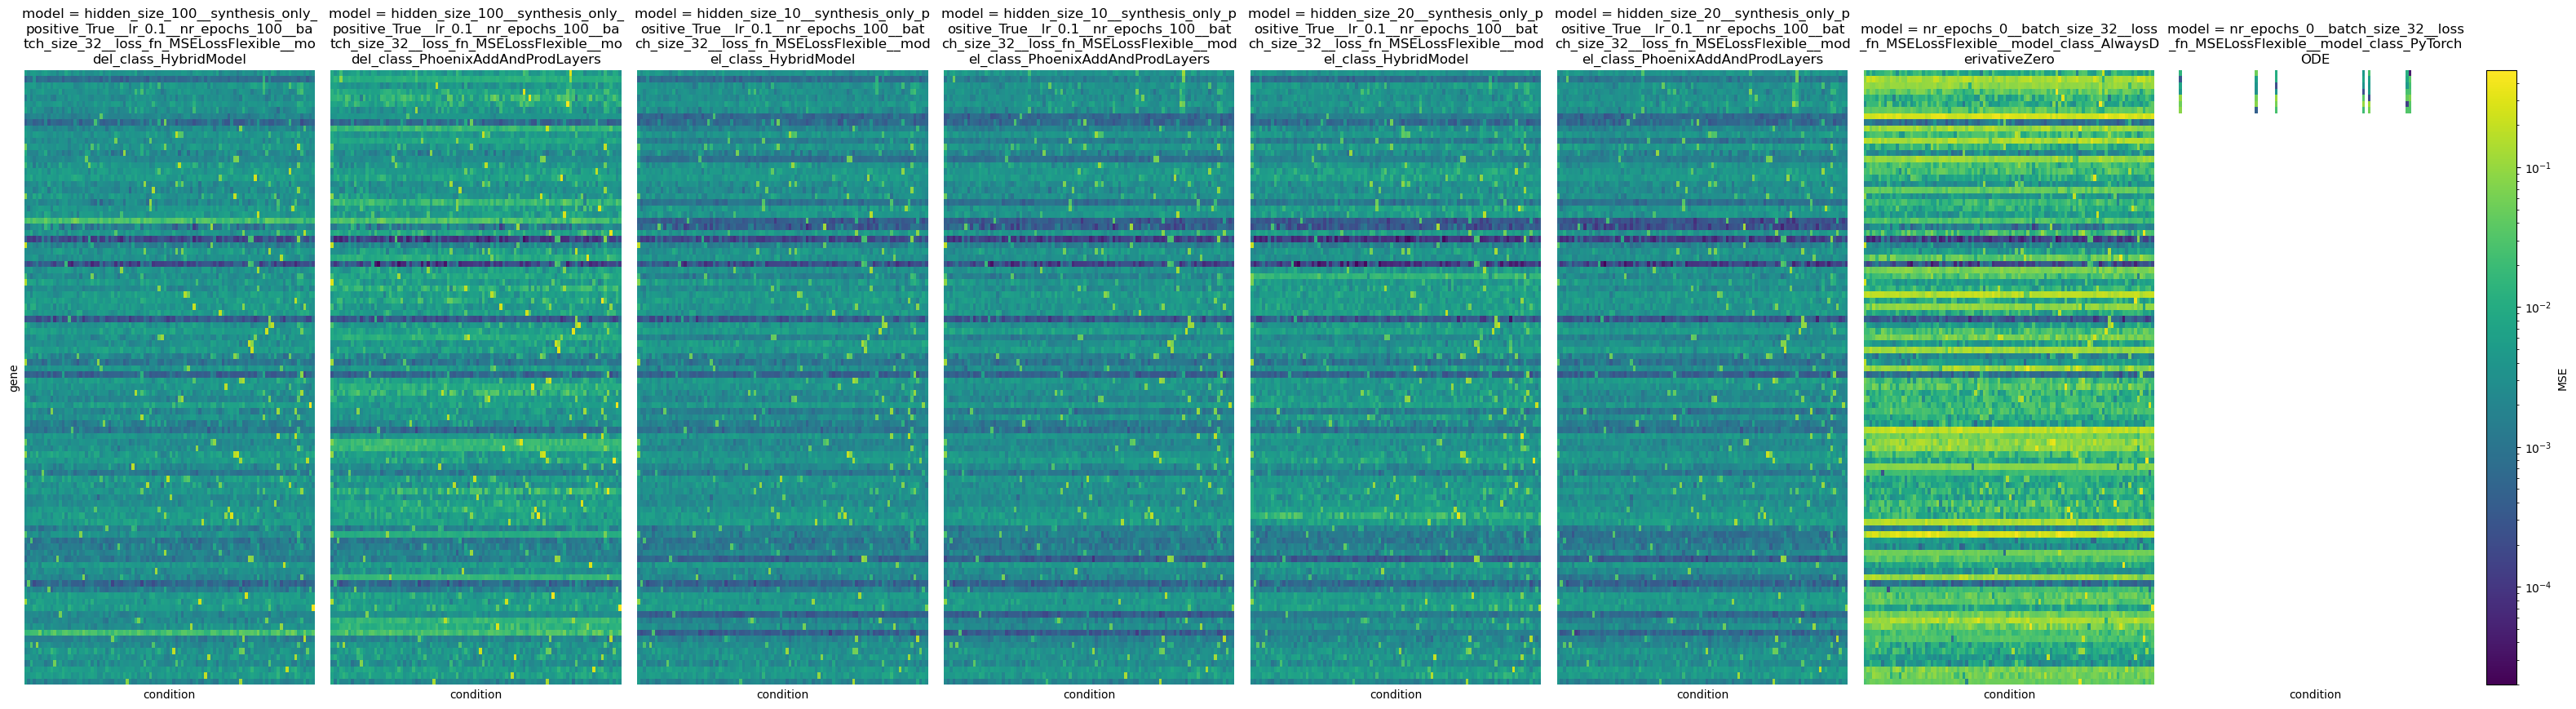

In [7]:
# Calculate the MSE heatmap that we've shown before
g = plot_per_gene_mse_heatmap(tidy_df_single_ko, robust_cmap=False)
wrap_titles(g)

### Double KO

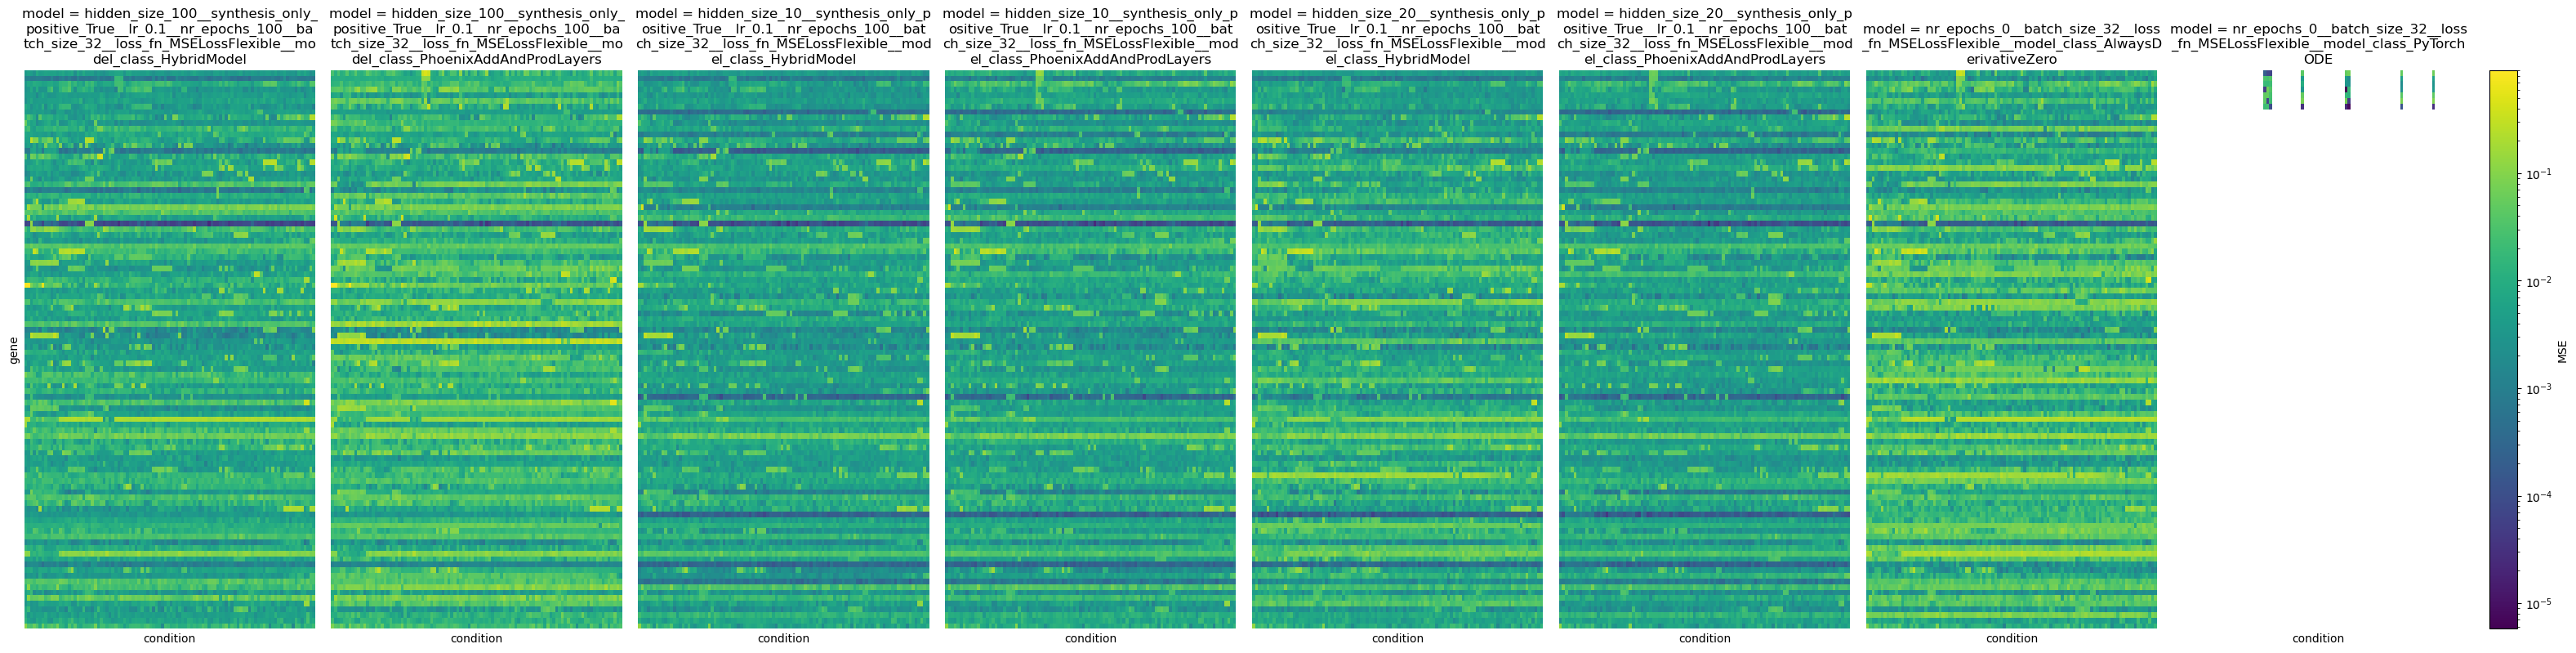

In [8]:
# Calculate the MSE heatmap that we've shown before
g = plot_per_gene_mse_heatmap(tidy_df_double_ko, robust_cmap=False)
wrap_titles(g)